In [5]:
import torch
import matplotlib.pyplot as plt

from ngo.trainingdata.GRF import ManufacturedSolution
from ngo.testproblems.steadydiffusion.manufacturedsolutions import *
from ngo.numericalanalysis.quadrature import GaussLegendreQuadrature

In [6]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
N_samples = 10
n_x = 10
n_y = 10
n_z = 10
N = n_x * n_y * n_z
Q_x = 99
Q_y = 99
Q_z = 99

n_elements_x = 3
n_elements_y = 3
n_elements_z = 3

quadrature_x = GaussLegendreQuadrature(Q=[Q_x], n_elements=[n_elements_x])
quadrature_y = GaussLegendreQuadrature(Q=[Q_y], n_elements=[n_elements_y])
quadrature_z = GaussLegendreQuadrature(Q=[Q_z], n_elements=[n_elements_z])

x = torch.tensor(quadrature_x.xi.reshape(quadrature_x.xi.shape[0],), device='cuda', dtype=torch.float32)
y = torch.tensor(quadrature_y.xi.reshape(quadrature_y.xi.shape[0],), device='cuda', dtype=torch.float32)
z = torch.tensor(quadrature_z.xi.reshape(quadrature_z.xi.shape[0],), device='cuda', dtype=torch.float32)

X = x,y


In [8]:
N_samples = 10
lambda_min = torch.tensor([0.1,0.1], device='cuda', dtype=torch.float32)
lambda_max = torch.tensor([0.1,0.1], device='cuda', dtype=torch.float32)
d = len(lambda_min)
b_min_u = -1 #torch.tensor([1], device='cuda', dtype=torch.float64)
b_max_u = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_min_u = 0 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_max_u  = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
device = 'cuda'
dtype = torch.float32
n = (3,3)

In [9]:
u = ManufacturedSolution(N_samples, d, lambda_min, lambda_max, b_min_u, b_max_u, c_min_u, c_max_u, device, dtype, n)

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, dtype=self.dtype, device=self.device)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, dtype=self.dtype, device=self.device)


In [10]:
torch.cuda.empty_cache()
u.forward(X)

tensor([[[-0.2808, -0.2911, -0.3103,  ..., -1.2414, -1.2502, -1.2546],
         [-0.2648, -0.2751, -0.2942,  ..., -1.2310, -1.2404, -1.2450],
         [-0.2361, -0.2463, -0.2653,  ..., -1.2122, -1.2224, -1.2276],
         ...,
         [-1.3086, -1.2995, -1.2821,  ..., -0.5076, -0.5059, -0.5048],
         [-1.2994, -1.2903, -1.2729,  ..., -0.4897, -0.4886, -0.4878],
         [-1.2937, -1.2846, -1.2672,  ..., -0.4799, -0.4792, -0.4786]],

        [[-0.2214, -0.2110, -0.1920,  ..., -0.7288, -0.7076, -0.6952],
         [-0.2331, -0.2225, -0.2031,  ..., -0.7278, -0.7070, -0.6950],
         [-0.2540, -0.2430, -0.2228,  ..., -0.7253, -0.7057, -0.6943],
         ...,
         [-0.7349, -0.7344, -0.7330,  ..., -1.1828, -1.1777, -1.1743],
         [-0.7248, -0.7244, -0.7232,  ..., -1.1978, -1.1926, -1.1891],
         [-0.7187, -0.7183, -0.7172,  ..., -1.2057, -1.2004, -1.1969]],

        [[-1.0390, -1.0459, -1.0573,  ..., -1.0784, -1.0798, -1.0802],
         [-1.0519, -1.0587, -1.0698,  ..., -1

In [11]:
b_min_theta = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
b_max_theta = 1 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_min_theta = 0 #torch.tensor([1], device='cuda', dtype=torch.float64)
c_max_theta  = 0.2 #torch.tensor([1], device='cuda', dtype=torch.float64)

In [12]:
theta = ManufacturedSolution(N_samples, d, lambda_min, lambda_max, b_min_theta, b_max_theta, c_min_theta, c_max_theta, device, dtype, n)

In [13]:
theta.forward(X)

tensor([[[1.0278, 1.0304, 1.0345,  ..., 0.8721, 0.8703, 0.8691],
         [1.0313, 1.0339, 1.0379,  ..., 0.8716, 0.8700, 0.8688],
         [1.0372, 1.0397, 1.0436,  ..., 0.8702, 0.8688, 0.8678],
         ...,
         [1.0951, 1.1014, 1.1123,  ..., 1.0940, 1.0959, 1.0966],
         [1.0937, 1.1000, 1.1110,  ..., 1.0883, 1.0902, 1.0908],
         [1.0925, 1.0989, 1.1098,  ..., 1.0849, 1.0867, 1.0873]],

        [[0.8549, 0.8611, 0.8719,  ..., 0.9528, 0.9434, 0.9379],
         [0.8559, 0.8621, 0.8730,  ..., 0.9578, 0.9483, 0.9428],
         [0.8572, 0.8635, 0.8743,  ..., 0.9662, 0.9565, 0.9509],
         ...,
         [1.0151, 1.0181, 1.0231,  ..., 0.9734, 0.9659, 0.9615],
         [1.0106, 1.0137, 1.0186,  ..., 0.9660, 0.9585, 0.9541],
         [1.0079, 1.0109, 1.0158,  ..., 0.9616, 0.9541, 0.9497]],

        [[0.9740, 0.9775, 0.9833,  ..., 0.9798, 0.9752, 0.9723],
         [0.9763, 0.9799, 0.9857,  ..., 0.9840, 0.9794, 0.9765],
         [0.9801, 0.9836, 0.9896,  ..., 0.9911, 0.9864, 0.

In [14]:
f = Forcing(theta, u)

In [15]:
f.forward(X)

tensor([[[  59.4283,   58.9443,   57.7277,  ..., -143.6660, -146.4199,
          -147.6087],
         [  70.3321,   69.8977,   68.7540,  ..., -133.8192, -136.9951,
          -138.4242],
         [  90.3023,   89.9584,   88.9478,  ..., -115.6410, -119.5725,
          -121.4326],
         ...,
         [-307.9361, -303.8325, -295.3378,  ...,   14.8185,   13.5945,
            12.9993],
         [-298.5166, -294.3078, -285.6435,  ...,   14.9308,   13.2717,
            12.4357],
         [-292.8738, -288.6124, -279.8656,  ...,   14.9544,   13.0621,
            12.0970]],

        [[ -78.1611,  -76.2403,  -72.4015,  ..., -137.0676, -117.5223,
          -106.7201],
         [ -85.8151,  -83.8741,  -79.9797,  ..., -138.0154, -118.6856,
          -107.9969],
         [ -99.6618,  -97.6882,  -93.7003,  ..., -139.3542, -120.4725,
          -110.0209],
         ...,
         [-162.0934, -161.2101, -159.1650,  ..., -232.8368, -225.4467,
          -221.0768],
         [-152.7315, -152.0229, -150.312

In [16]:
n = torch.tensor([0,1], device='cuda', dtype=torch.float32)
eta = NeumannBC(n, theta, u)

In [18]:
eta.forward(X).shape

torch.Size([10, 99, 99])

In [126]:
g = DirichletBC(theta, u)

In [127]:
g.forward(X)

tensor([[[ 0.8740,  0.8808,  0.8924,  ...,  0.4413,  0.4305,  0.4244],
         [ 0.8852,  0.8921,  0.9037,  ...,  0.4480,  0.4371,  0.4310],
         [ 0.9047,  0.9118,  0.9236,  ...,  0.4597,  0.4486,  0.4423],
         ...,
         [ 0.6046,  0.6103,  0.6200,  ...,  0.4247,  0.4213,  0.4192],
         [ 0.6094,  0.6151,  0.6247,  ...,  0.4375,  0.4341,  0.4321],
         [ 0.6116,  0.6172,  0.6267,  ...,  0.4443,  0.4409,  0.4388]],

        [[ 0.7557,  0.7618,  0.7722,  ...,  1.3921,  1.3726,  1.3611],
         [ 0.7699,  0.7761,  0.7866,  ...,  1.3912,  1.3716,  1.3602],
         [ 0.7956,  0.8019,  0.8125,  ...,  1.3877,  1.3680,  1.3565],
         ...,
         [ 1.5119,  1.5101,  1.5048,  ...,  1.5447,  1.5363,  1.5305],
         [ 1.5141,  1.5122,  1.5067,  ...,  1.5485,  1.5398,  1.5339],
         [ 1.5141,  1.5122,  1.5067,  ...,  1.5494,  1.5406,  1.5346]],

        [[ 1.1798,  1.1902,  1.2074,  ...,  1.0073,  0.9901,  0.9798],
         [ 1.1871,  1.1974,  1.2143,  ...,  0

In [128]:
sample = 0

u_data = u.forward(X)
theta_data = theta.forward(X)
f_data = f.forward(X)
eta_data = eta.forward(X)
g_data = g.forward(X)

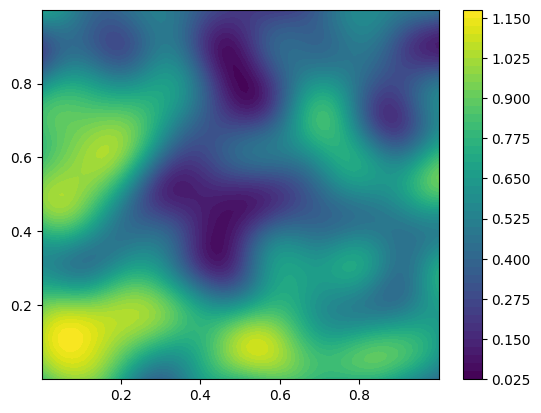

In [129]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), u_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

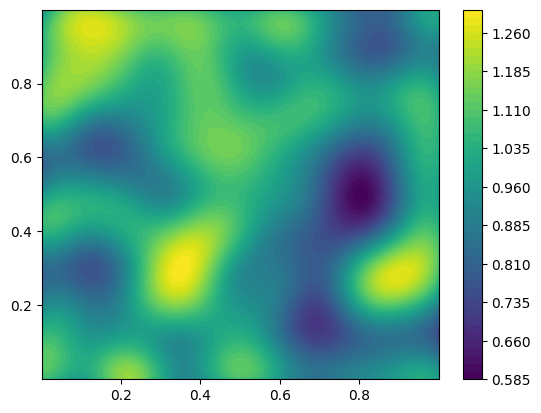

In [130]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), theta_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

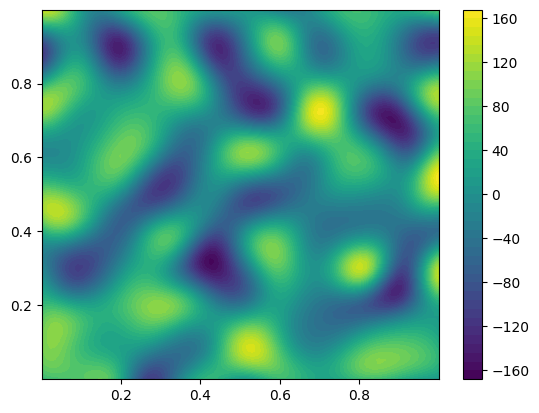

In [131]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), f_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

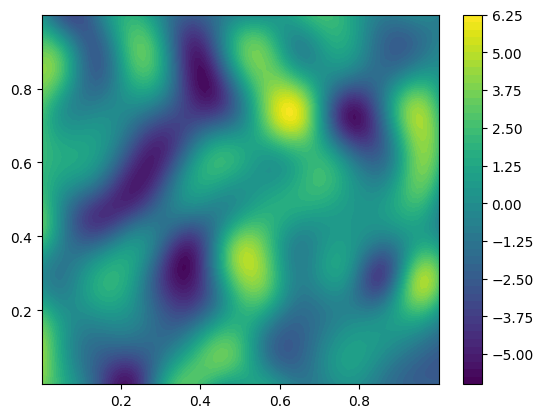

In [132]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), eta_data[sample].cpu().numpy(), levels=50)
plt.colorbar()

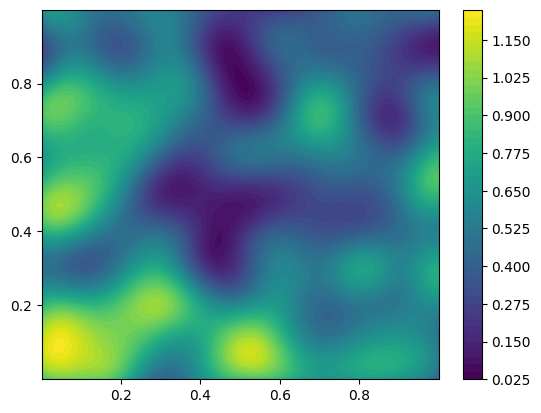

In [133]:
plt.contourf(x.cpu().numpy(), y.cpu().numpy(), g_data[sample].cpu().numpy(), levels=50)
plt.colorbar()